In [85]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
from scipy.stats import bootstrap

data = pd.read_csv("../experiment_results.csv")

In [83]:
data["Error (Scaled to 0)"] = abs(data["Actual Percent Diff"] - data["Reported Percent Diff"]) + 1
data["Error (Cleveland-McGill)"] = abs(data["Actual Percent Diff"] - data["Reported Percent Diff"]) + 1/8

#math.log doesn't work on series, so have to scale each data point individually :(
for i in range(len(data)):
    data.loc[i, "Error (Scaled to 0)"] = math.log(data["Error (Scaled to 0)"][i], 2)
    data.loc[i, "Error (Cleveland-McGill)"] = math.log(data["Error (Cleveland-McGill)"][i],2)

#get the means of each visualization group
meansPD = data.groupby("Visualization Type")[["Error (Scaled to 0)", "Error (Cleveland-McGill)"]].mean()

#data variables for matplotlib
means0 = []
lows0 = []
highs0 = []
meansCMG = []
lowsCMG = []
highsCMG = []
yAxis = ["Needle", "Barbell", "House", "Senate"]

#get data for each visualization and put it in each series
for i in range(4):
    visData = data[data["Visualization Type"] == i + 1]

    #get the bootstrap sampling
    ci0 = bootstrap((visData["Error (Scaled to 0)"],), np.mean, confidence_level=0.95)
    ciCMG = bootstrap((visData["Error (Cleveland-McGill)"],), np.mean, confidence_level=0.95)

    #get confidence interval data
    lows0.append(ci0.confidence_interval.low)
    highs0.append(ci0.confidence_interval.high)
    lowsCMG.append(ciCMG.confidence_interval.low)
    highsCMG.append(ciCMG.confidence_interval.high)
    means0.append(meansPD.loc[i + 1, "Error (Scaled to 0)"])
    meansCMG.append(meansPD.loc[i + 1, "Error (Cleveland-McGill)"])

print(lows0, highs0, means0)

[np.float64(2.8938193960080687), np.float64(2.491977011984769), np.float64(2.4323139455402343), np.float64(2.706419700110661)] [np.float64(3.4816979420007437), np.float64(3.117590321923989), np.float64(2.9405760325621606), np.float64(3.225553026845102)] [np.float64(3.1842569358047434), np.float64(2.7896294727848514), np.float64(2.6759045666444274), np.float64(2.9623154937406495)]


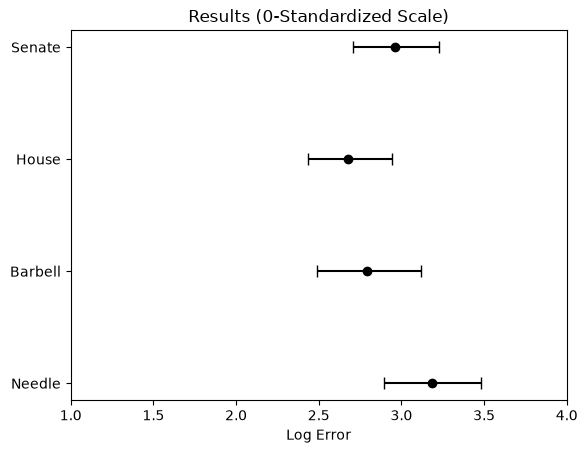

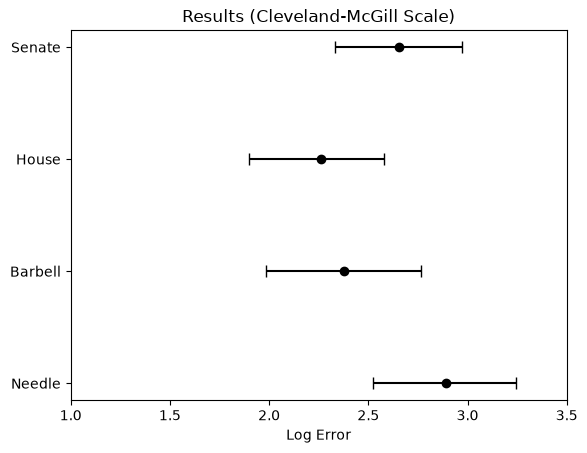

In [112]:
#matplotlib coding block
left_error0 = np.subtract(means0, lows0)
right_error0 = np.subtract(highs0, means0)

fig, ax = plt.subplots()

ax.set_xlim(1.0, 4.0)
ax.set_xlabel("Log Error")
ax.set_title("Results (0-Standardized Scale)")

ax.errorbar(
    means0,
    yAxis,
    fmt='o',
    xerr=[left_error0, right_error0],
    capsize=4,
    color='black'
)

plt.show()

left_errorCMG = np.subtract(meansCMG, lowsCMG)
right_errorCMG = np.subtract(highsCMG, meansCMG)

fig, ax = plt.subplots()

ax.set_xlim(1.0, 3.5)
ax.set_xlabel("Log Error")
ax.set_title("Results (Cleveland-McGill Scale)")

ax.errorbar(
    meansCMG,
    yAxis,
    fmt='o',
    xerr=[left_errorCMG, right_errorCMG],
    capsize=4,
    color='black'
)

plt.show()